# Image Classification: 10 Groups of Animals, Plants and Fungi

Fine-tuning a pretrained **ConvNeXt-Tiny** to classify nature photos into 10 taxonomic groups.

- **Data:** 10,000 training images (1,000 per class) and 2,000 test images
- **Classes:** Amphibia, Animalia, Arachnida, Aves, Fungi, Insecta, Mammalia, Mollusca, Plantae, Reptilia
- **Metric:** weighted F1 score

**Pipeline:** stratified train/validation split → augmentation → transfer learning with a pretrained ConvNeXt → mixed-precision fine-tuning with label smoothing and a cosine learning-rate schedule → evaluation (F1, confusion matrix) → test predictions with flip test-time augmentation.

*Run on Kaggle with a GPU accelerator and Internet enabled (to download the pretrained weights).*

## 1. Setup

In [1]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from PIL import Image
from tqdm.auto import tqdm

DATA_DIR = "/kaggle/input/competitions/deep-learning-practice-week-9-image-c-lassifica"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")
OUT_DIR = "/kaggle/working"

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 10
VAL_FRACTION = 0.15

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Device: cuda Tesla T4


## 2. Data
`ImageFolder` reads one sub-folder per class and assigns labels in **alphabetical order** (Amphibia = 0 … Reptilia = 9), which is the label order used in the submission file.

In [2]:
base = datasets.ImageFolder(TRAIN_DIR)
class_names = base.classes
targets = np.array(base.targets)
print("Classes:", dict(enumerate(class_names)))
print("Training images:", len(base))
print(pd.Series(targets).map(dict(enumerate(class_names))).value_counts().sort_index())

Classes: {0: 'Amphibia', 1: 'Animalia', 2: 'Arachnida', 3: 'Aves', 4: 'Fungi', 5: 'Insecta', 6: 'Mammalia', 7: 'Mollusca', 8: 'Plantae', 9: 'Reptilia'}
Training images: 9999
Amphibia     1000
Animalia     1000
Arachnida    1000
Aves         1000
Fungi         999
Insecta      1000
Mammalia     1000
Mollusca     1000
Plantae      1000
Reptilia     1000
Name: count, dtype: int64


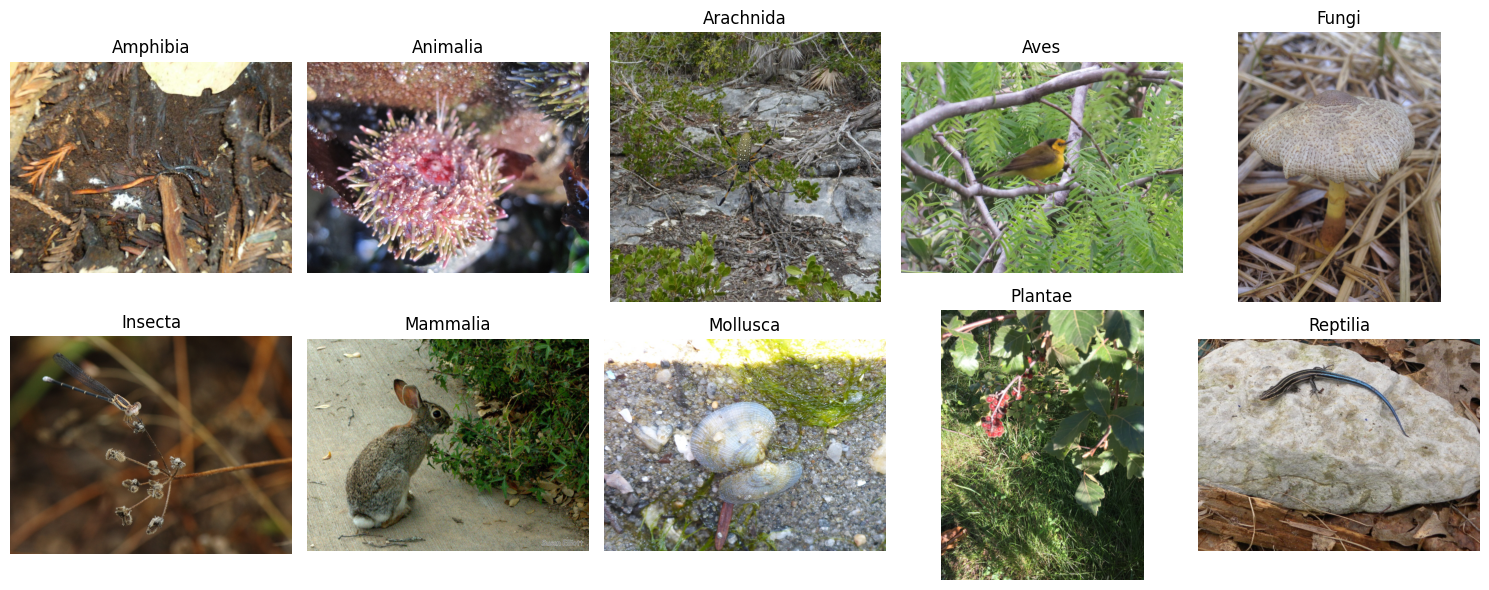

In [3]:
# Look at a few training images
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, cls_idx in zip(axes.ravel(), range(len(class_names))):
    path = base.samples[np.where(targets == cls_idx)[0][0]][0]
    ax.imshow(Image.open(path)); ax.set_title(class_names[cls_idx]); ax.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "sample_images.png"), dpi=100); plt.show()

## 3. Train/validation split and augmentation
A **stratified** 85/15 split keeps every class equally represented in validation. Training images get random crops, flips, small rotations and colour jitter, so the model sees more variety; validation images are only resized and centre-cropped. Both use ImageNet normalisation, matching the pretrained weights.

In [4]:
train_idx, val_idx = train_test_split(np.arange(len(base)), test_size=VAL_FRACTION,
                                      stratify=targets, random_state=SEED)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.14)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = Subset(datasets.ImageFolder(TRAIN_DIR, transform=train_tf), train_idx)
val_ds = Subset(datasets.ImageFolder(TRAIN_DIR, transform=eval_tf), val_idx)
workers = min(4, os.cpu_count())
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=workers, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=workers, pin_memory=True)
print(f"Train: {len(train_ds)}  Validation: {len(val_ds)}")

Train: 8499  Validation: 1500


## 4. Model: pretrained ConvNeXt-Tiny
ConvNeXt-Tiny (28M parameters) is a modern CNN pretrained on ImageNet. The final layer is replaced with a 10-class layer. The pretrained backbone gets a smaller learning rate than the new head, so its features are adjusted gently rather than overwritten.

In [5]:
model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
model.classifier[2] = nn.Linear(model.classifier[2].in_features, len(class_names))
model = model.to(device)

head_params = list(model.classifier.parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": 1e-4},
    {"params": head_params, "lr": 1e-3},
], weight_decay=0.05)

steps = EPOCHS * len(train_dl)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[1e-4, 1e-3], total_steps=steps, pct_start=0.1)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)  # softer targets reduce overconfidence
scaler = torch.amp.GradScaler("cuda")
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 229MB/s]  


Parameters: 27.8M


## 5. Training
Each epoch trains with **mixed precision** (faster and lighter on memory), then measures validation accuracy and **weighted F1**, the competition metric. The weights with the best validation F1 are saved.

In [6]:
def evaluate(model, loader):
    model.eval()
    preds, labels, total_loss = [], [], 0.0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            total_loss += criterion(out, y).item() * len(y)
            preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return total_loss / len(labels), (preds == labels).mean(), f1_score(labels, preds, average="weighted"), preds, labels

history, best_f1 = [], 0.0
for epoch in range(1, EPOCHS + 1):
    model.train(); start = time.time(); running = 0.0
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch}/{EPOCHS}", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item() * len(y)

    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_dl)
    history.append({"epoch": epoch, "train_loss": running / len(train_ds), "val_loss": val_loss, "val_acc": val_acc, "val_f1": val_f1})
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), os.path.join(OUT_DIR, "best_model.pt"))
    print(f"Epoch {epoch:2d} | train loss {running / len(train_ds):.4f} | val loss {val_loss:.4f} | "
          f"val acc {val_acc:.4f} | val F1 {val_f1:.4f} | {time.time() - start:.0f}s")

print(f"Best validation weighted F1: {best_f1:.4f}")

Epoch 1/10:   0%|          | 0/133 [00:00<?, ?it/s]

Epoch  1 | train loss 1.4992 | val loss 0.8132 | val acc 0.8847 | val F1 0.8851 | 75s


Epoch 2/10:   0%|          | 0/133 [00:00<?, ?it/s]

Epoch  2 | train loss 0.7908 | val loss 0.7422 | val acc 0.9167 | val F1 0.9163 | 60s


Epoch 3/10:   0%|          | 0/133 [00:00<?, ?it/s]

Epoch  3 | train loss 0.6685 | val loss 0.7153 | val acc 0.9193 | val F1 0.9193 | 60s


... (10 outputs left out)

Epoch 9/10:   0%|          | 0/133 [00:00<?, ?it/s]

Epoch  9 | train loss 0.5345 | val loss 0.7071 | val acc 0.9173 | val F1 0.9174 | 61s


Epoch 10/10:   0%|          | 0/133 [00:00<?, ?it/s]

Epoch 10 | train loss 0.5326 | val loss 0.7064 | val acc 0.9173 | val F1 0.9174 | 60s
Best validation weighted F1: 0.9193


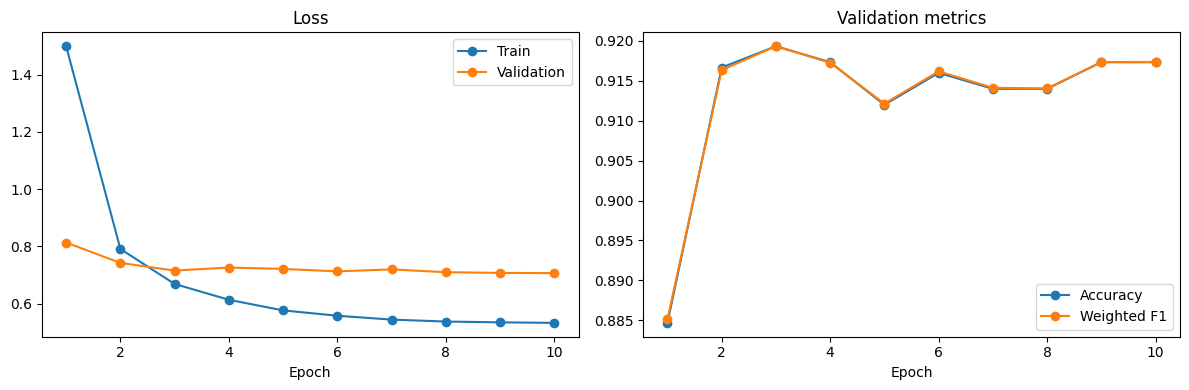

In [7]:
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist.train_loss, marker="o", label="Train"); ax[0].plot(hist.epoch, hist.val_loss, marker="o", label="Validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist.epoch, hist.val_acc, marker="o", label="Accuracy"); ax[1].plot(hist.epoch, hist.val_f1, marker="o", label="Weighted F1")
ax[1].set_title("Validation metrics"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=100); plt.show()

## 6. Evaluation of the best model

Validation accuracy: 0.9193   weighted F1: 0.9193

              precision    recall  f1-score   support

    Amphibia      0.904     0.947     0.925       150
    Animalia      0.930     0.880     0.904       150
   Arachnida      0.979     0.953     0.966       150
        Aves      0.894     0.960     0.926       150
       Fungi      0.945     0.913     0.929       150
     Insecta      0.939     0.920     0.929       150
    Mammalia      0.920     0.920     0.920       150
    Mollusca      0.885     0.873     0.879       150
     Plantae      0.882     0.900     0.891       150
    Reptilia      0.921     0.927     0.924       150

    accuracy                          0.919      1500
   macro avg      0.920     0.919     0.919      1500
weighted avg      0.920     0.919     0.919      1500



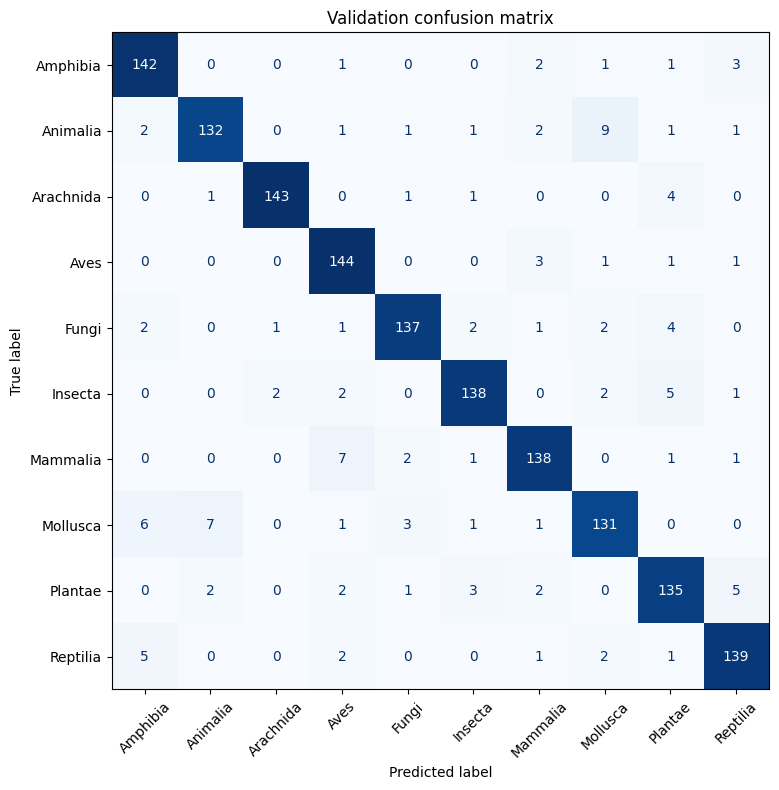

In [8]:
model.load_state_dict(torch.load(os.path.join(OUT_DIR, "best_model.pt")))
_, val_acc, val_f1, preds, labels = evaluate(model, val_dl)
print(f"Validation accuracy: {val_acc:.4f}   weighted F1: {val_f1:.4f}\n")
print(classification_report(labels, preds, target_names=class_names, digits=3))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(labels, preds), display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Validation confusion matrix"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=100); plt.show()

## 7. Test predictions
Each test image is predicted twice, as is and flipped horizontally, and the two probability outputs are averaged (**test-time augmentation**). Rows follow the order of the sample submission.

In [9]:
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
test_files = {os.path.splitext(f)[0]: f for f in os.listdir(TEST_DIR)}

model.eval(); results = {}
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    for image_id in tqdm(sample_sub["Image_ID"]):
        img = eval_tf(Image.open(os.path.join(TEST_DIR, test_files[image_id])).convert("RGB")).unsqueeze(0).to(device)
        probs = model(img).softmax(1) + model(torch.flip(img, dims=[3])).softmax(1)
        results[image_id] = int(probs.argmax(1).item())

submission = pd.DataFrame({"Image_ID": sample_sub["Image_ID"], "Label": sample_sub["Image_ID"].map(results)})
submission.to_csv(os.path.join(OUT_DIR, "submission.csv"), index=False)
print(submission.head())
print(submission["Label"].map(dict(enumerate(class_names))).value_counts())

  0%|          | 0/2000 [00:00<?, ?it/s]

     Image_ID  Label
0  Image_0001      0
1  Image_0002      7
2  Image_0003      5
3  Image_0004      1
4  Image_0005      4
Label
Aves         216
Amphibia     213
Mollusca     209
Insecta      199
Reptilia     199
Mammalia     197
Arachnida    195
Fungi        195
Plantae      191
Animalia     186
Name: count, dtype: int64


## 8. Summary
The best validation weighted F1 is printed above. Ideas to improve further: a larger input size (e.g. 288), a larger backbone (ConvNeXt-Small), more epochs, or MixUp/CutMix augmentation.